In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(
    "CAR DETAILS FROM CAR DEKHO.csv"
)

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (4340, 8)

Column Names:
Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 4340
Number of Columns: 8


In [7]:
print(df.columns.tolist())

['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [9]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [10]:
df.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


In [11]:
print(df.isnull().sum())

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

name             0.0
year             0.0
selling_price    0.0
km_driven        0.0
fuel             0.0
seller_type      0.0
transmission     0.0
owner            0.0
dtype: float64


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 763


In [14]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3577, 8)


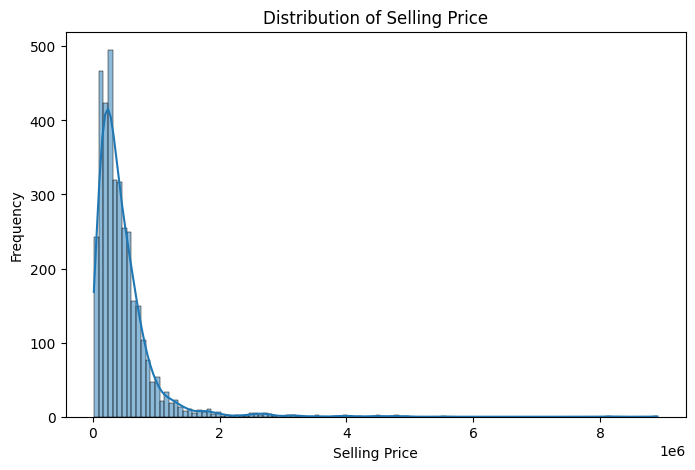

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df['selling_price'], kde=True)

plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

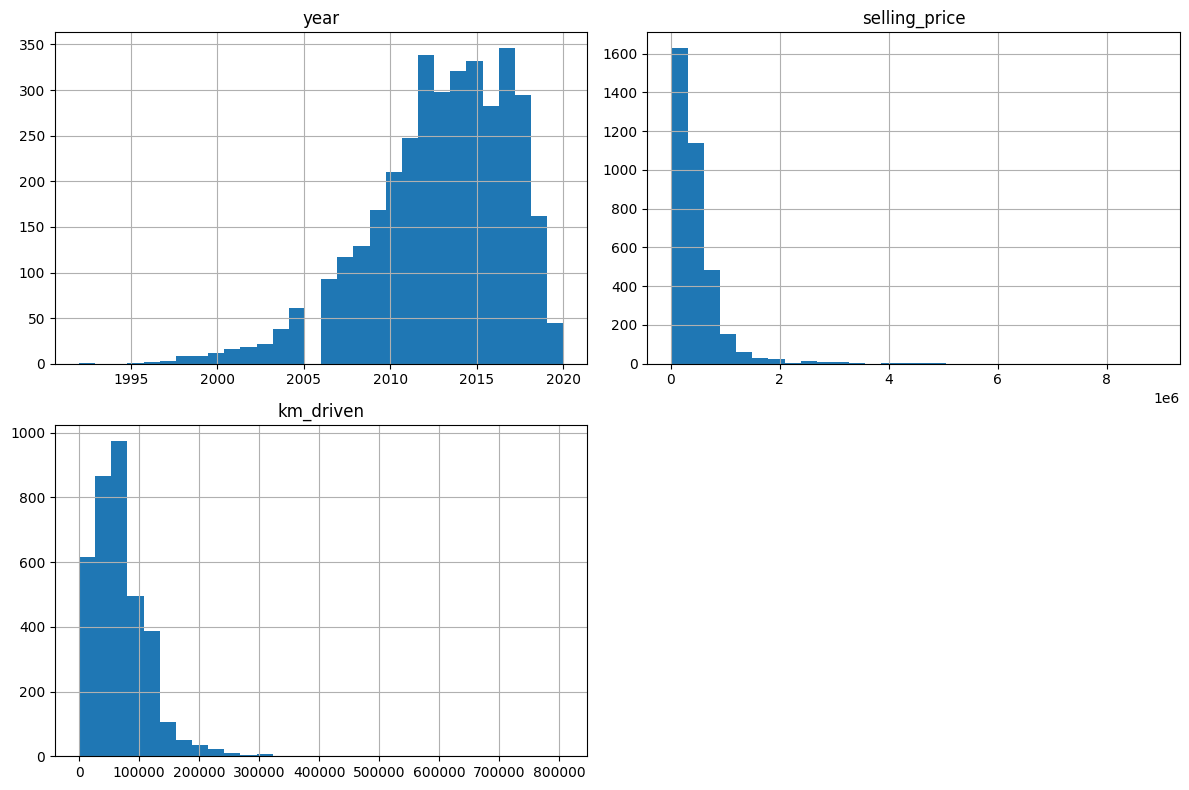

In [16]:
numerical_columns = [
    'year',
    'selling_price',
    'km_driven'
]

df[numerical_columns].hist(
    figsize=(12,8),
    bins=30
)

plt.tight_layout()
plt.show()

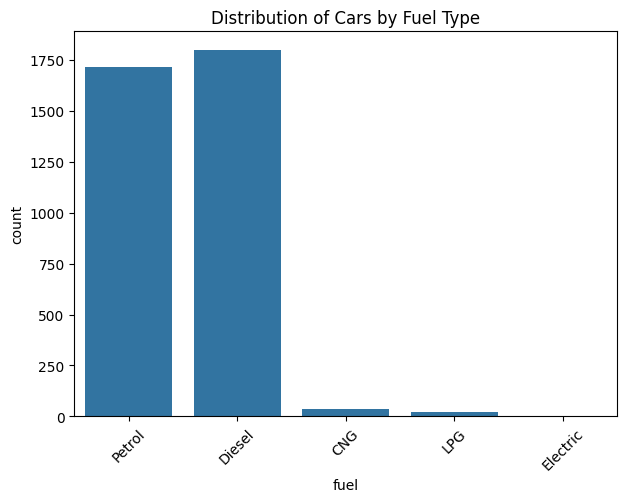

In [17]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='fuel')

plt.title("Distribution of Cars by Fuel Type")
plt.xticks(rotation=45)

plt.show()

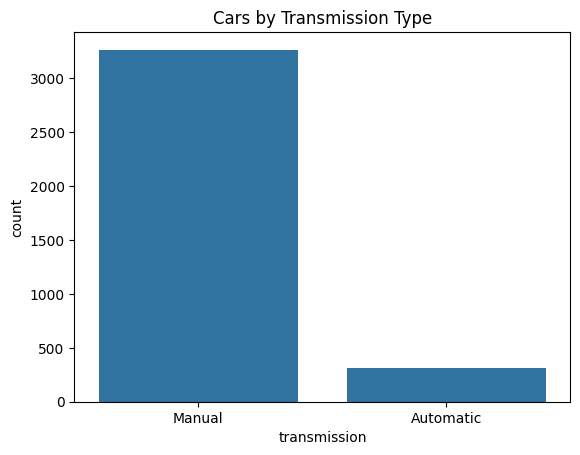

In [18]:
sns.countplot(data=df, x='transmission')

plt.title("Cars by Transmission Type")
plt.show()

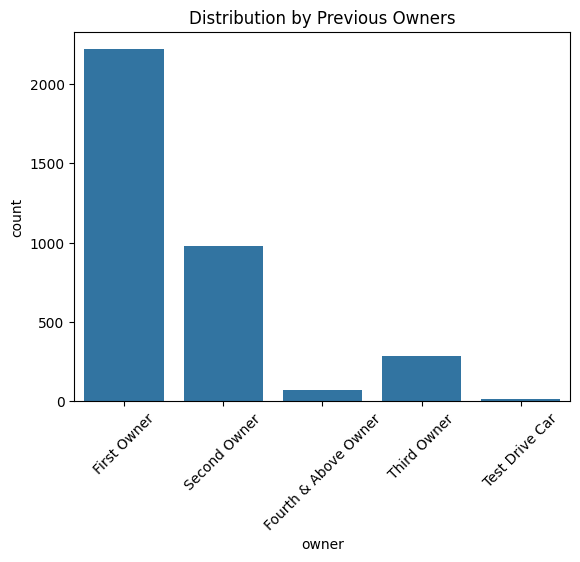

In [19]:
sns.countplot(data=df, x='owner')

plt.title("Distribution by Previous Owners")
plt.xticks(rotation=45)

plt.show()

In [25]:
numerical_columns = [
    'selling_price',
    'km_driven',
    'year'
]

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Column: selling_price
Lower Limit: -400000.0
Upper Limit: 1200000.0
Number of Outliers: 170

Column: km_driven
Lower Limit: -45000.0
Upper Limit: 171000.0
Number of Outliers: 106

Column: year
Lower Limit: 2001.0
Upper Limit: 2025.0
Number of Outliers: 37


In [26]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    percentage = (count / len(df)) * 100

    print(
        col,
        "Outliers:", count,
        "Percentage:", round(percentage, 2), "%"
    )

selling_price Outliers: 170 Percentage: 4.75 %
km_driven Outliers: 106 Percentage: 2.96 %
year Outliers: 37 Percentage: 1.03 %


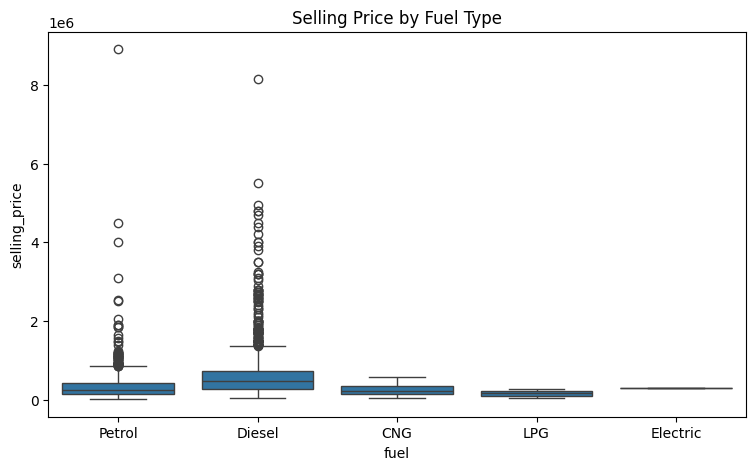

In [20]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='fuel',
    y='selling_price'
)

plt.title("Selling Price by Fuel Type")
plt.show()

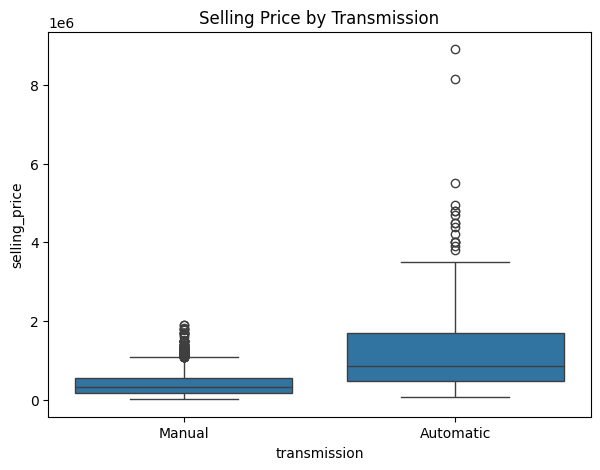

In [21]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x='transmission',
    y='selling_price'
)

plt.title("Selling Price by Transmission")
plt.show()

In [27]:
price_outliers = df[
    df['selling_price'] > 1200000
]

price_outliers.sort_values(
    by='selling_price',
    ascending=False
).head(20)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3872,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000,Petrol,Dealer,Automatic,First Owner
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Dealer,Automatic,First Owner
3969,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Dealer,Automatic,First Owner
555,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
3453,BMW 5 Series 520d Luxury Line,2018,4800000,9422,Diesel,Individual,Automatic,First Owner
3883,BMW 5 Series 520d Luxury Line,2019,4800000,12999,Diesel,Dealer,Automatic,First Owner
963,Audi A5 Sportback,2020,4700000,1500,Diesel,Individual,Automatic,First Owner
101,Mercedes-Benz E-Class Exclusive E 200 BSIV,2018,4500000,9800,Petrol,Dealer,Automatic,First Owner
4047,Volvo XC 90 D5 Inscription BSIV,2017,4500000,80000,Diesel,Individual,Automatic,First Owner
539,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,2014,4400000,100000,Diesel,Individual,Automatic,Second Owner


In [28]:
km_outliers = df[
    df['km_driven'] > 171000
]

km_outliers.sort_values(
    by='km_driven',
    ascending=False
).head(20)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
1243,Maruti Swift VXI BSIII,2009,250000,806599,Petrol,Dealer,Manual,First Owner
525,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
3679,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000,Diesel,Individual,Manual,Third Owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
2394,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000,Diesel,Individual,Manual,First Owner
3718,Toyota Innova 2.5 GX 8 STR BSIV,2009,420000,347089,Diesel,Dealer,Manual,First Owner
1674,Volkswagen Jetta 2.0 TDI Comfortline,2011,350000,312000,Diesel,Individual,Manual,Third Owner
1101,Tata Indica DLS,2006,85000,300000,Diesel,Individual,Manual,Second Owner
3994,Tata Indica GLS BS IV,2010,75000,300000,Petrol,Individual,Manual,Third Owner
3898,Tata Indica GLS BS IV,2010,90000,300000,Petrol,Individual,Manual,Third Owner


In [29]:
year_outliers = df[
    df['year'] < 2001
]

year_outliers.sort_values(
    by='year'
)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3334,Maruti 800 AC BSII,1992,50000,100000,Petrol,Individual,Manual,Fourth & Above Owner
631,Maruti Gypsy E MG410W ST,1995,95000,100000,Petrol,Individual,Manual,Second Owner
2972,Mahindra Jeep MM 540,1996,200000,60000,Diesel,Individual,Manual,First Owner
61,Mahindra Jeep CL 500 MDI,1996,250000,35000,Diesel,Individual,Manual,Second Owner
1669,Mahindra Jeep CL 500 MDI,1997,150000,120000,Diesel,Individual,Manual,Third Owner
3550,Maruti Esteem AX,1997,79000,70000,Petrol,Individual,Automatic,First Owner
3661,Maruti 800 Std,1997,50000,80000,Petrol,Individual,Manual,Second Owner
1699,Maruti Omni 5 Str STD LPG,1998,50000,35000,LPG,Individual,Manual,Second Owner
3371,Honda City 1.3 EXI,1998,85000,120000,Petrol,Individual,Manual,Second Owner
3532,Maruti Zen LXI,1998,80000,120000,Petrol,Individual,Manual,Second Owner


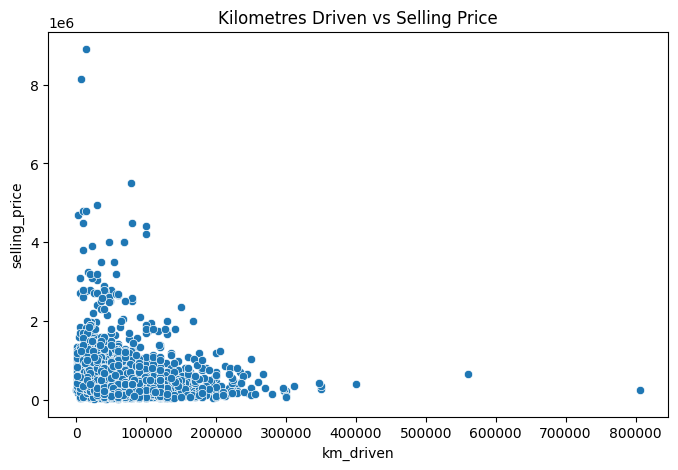

In [22]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='km_driven',
    y='selling_price'
)

plt.title("Kilometres Driven vs Selling Price")
plt.show()

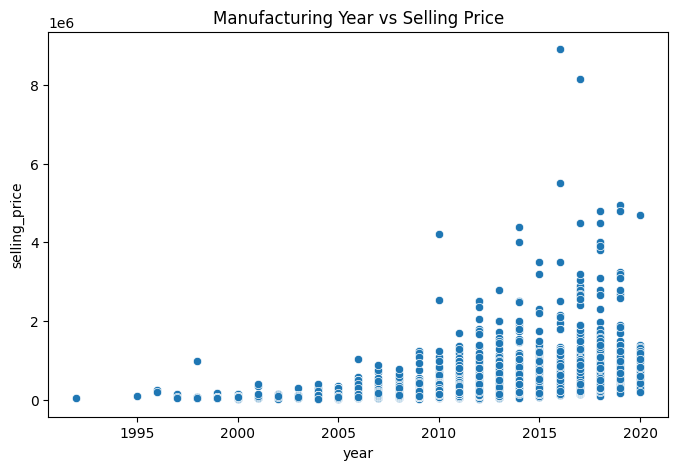

In [23]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='year',
    y='selling_price'
)

plt.title("Manufacturing Year vs Selling Price")
plt.show()

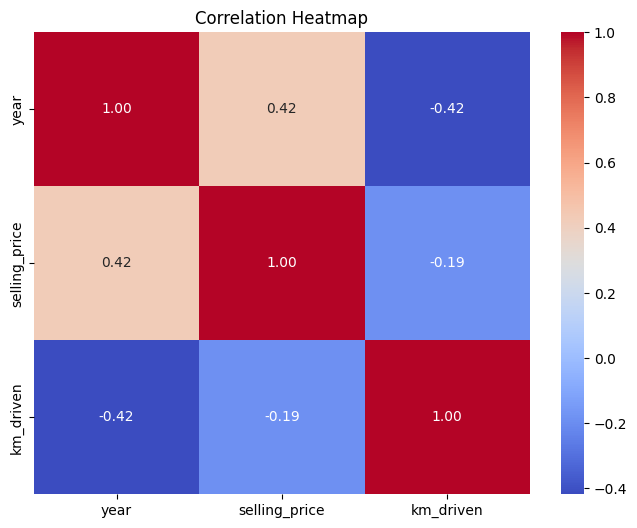

In [24]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [30]:
df_clean = df.copy()

print(df_clean.shape)

(3577, 8)


In [31]:
df_clean['brand'] = df_clean['name'].str.split().str[0]

df_clean[['name', 'brand']].head(10)

,name,brand
0,Maruti 800 AC,Maruti
1,Maruti Wagon R LXI Minor,Maruti
2,Hyundai Verna 1.6 SX,Hyundai
3,Datsun RediGO T Option,Datsun
4,Honda Amaze VX i-DTEC,Honda
5,Maruti Alto LX BSIII,Maruti
6,Hyundai Xcent 1.2 Kappa S,Hyundai
7,Tata Indigo Grand Petrol,Tata
8,Hyundai Creta 1.6 VTVT S,Hyundai
9,Maruti Celerio Green VXI,Maruti


In [32]:
print("Unique brands:", df_clean['brand'].nunique())

print(df_clean['brand'].value_counts().head(15))

Unique brands: 29
brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Nissan          52
Skoda           49
Fiat            32
Audi            31
Datsun          29
Name: count, dtype: int64


In [33]:
current_year = 2026

df_clean['car_age'] = current_year - df_clean['year']

df_clean[['year', 'car_age']].head(10)

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12
5,2007,19
6,2016,10
7,2014,12
8,2015,11
9,2017,9


In [34]:
df_clean['km_per_year'] = (
    df_clean['km_driven'] /
    df_clean['car_age'].replace(0, 1)
)

df_clean[['km_driven', 'car_age', 'km_per_year']].head(10)

,km_driven,car_age,km_per_year
0,70000,19,3684.210526
1,50000,19,2631.578947
2,100000,14,7142.857143
3,46000,9,5111.111111
4,141000,12,11750.000000
5,125000,19,6578.947368
6,25000,10,2500.000000
7,60000,12,5000.000000
8,25000,11,2272.727273
9,78000,9,8666.666667


In [35]:
df_clean.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age,km_per_year
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,19,3684.210526
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,19,2631.578947
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,14,7142.857143
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,9,5111.111111
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,12,11750.000000


In [36]:
print("Updated Shape:", df_clean.shape)

print("\nUpdated Columns:")
print(df_clean.columns.tolist())

print("\nMissing Values:")
print(df_clean.isnull().sum())

Updated Shape: (3577, 11)

Updated Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'car_age', 'km_per_year']

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
brand            0
car_age          0
km_per_year      0
dtype: int64


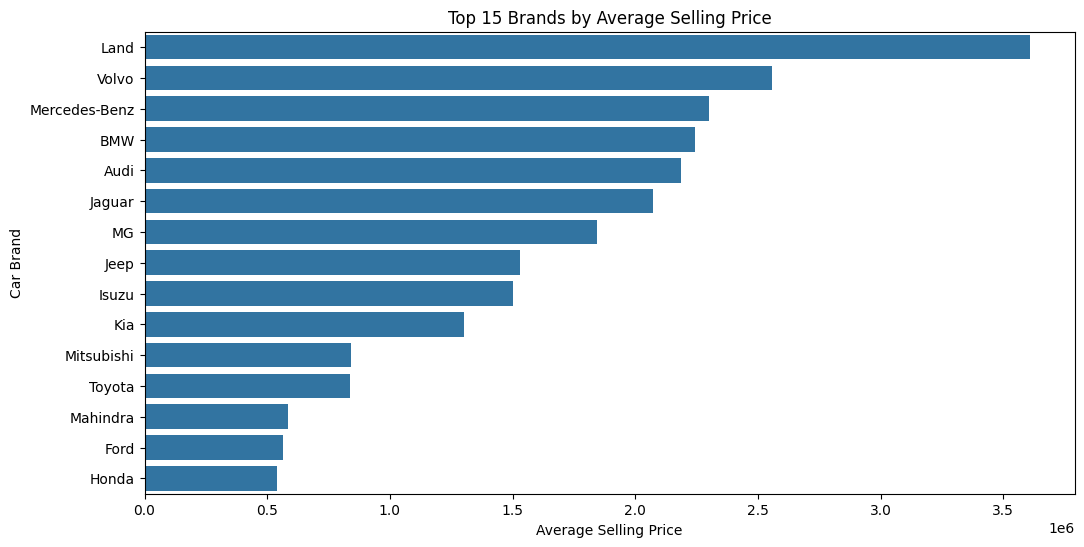

In [37]:
brand_price = (
    df_clean.groupby('brand')['selling_price']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=brand_price.values,
    y=brand_price.index
)

plt.title("Top 15 Brands by Average Selling Price")
plt.xlabel("Average Selling Price")
plt.ylabel("Car Brand")

plt.show()

In [38]:
# Select input features
features = [
    'brand',
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'car_age',
    'km_driven'
]

X = df_clean[features]

# Select target variable
y = df_clean['selling_price']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

Input Features Shape: (3577, 7)
Target Variable Shape: (3577,)

Input Features:


,brand,fuel,seller_type,transmission,owner,car_age,km_driven
0,Maruti,Petrol,Individual,Manual,First Owner,19,70000
1,Maruti,Petrol,Individual,Manual,First Owner,19,50000
2,Hyundai,Diesel,Individual,Manual,First Owner,14,100000
3,Datsun,Petrol,Individual,Manual,First Owner,9,46000
4,Honda,Diesel,Individual,Manual,Second Owner,12,141000



Target Variable:


0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

In [39]:
categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
Numerical Features: ['car_age', 'km_driven']


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2861, 7)
X_test: (716, 7)
y_train: (2861,)
y_test: (716,)


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

In [43]:
X_train_transformed = preprocessor.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_transformed.shape)

Original training shape: (2861, 7)
Transformed training shape: (2861, 43)


In [44]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [45]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', ColumnTransformer(
            transformers=[
                ('cat', OneHotEncoder(handle_unknown='ignore'),
                 categorical_features),
                ('num', StandardScaler(), numerical_features)
            ]
        )),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


In [46]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

print(results_df)

               Model            MAE           RMSE  R2 Score
2      Random Forest  159204.467506  366340.635900  0.583385
3  Gradient Boosting  157754.250735  379171.773162  0.553690
0  Linear Regression  179642.899003  384722.646226  0.540527
1      Decision Tree  199731.959198  475334.798428  0.298604


In [47]:
from sklearn.model_selection import RandomizedSearchCV

In [48]:
param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.8, 1.0]
}

In [49]:
rf_pipeline = trained_models['Random Forest']

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [10, 15, ...], 'model__max_features': ['sqrt', 0.8, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strat

In [50]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation R2 Score:")
print(random_search.best_score_)

Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 20}

Best Cross-Validation R2 Score:
0.6528051268184051


In [51]:
best_model = random_search.best_estimator_

In [52]:
y_pred_tuned = best_model.predict(X_test)

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)

rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))

r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE:", mae_tuned)
print("RMSE:", rmse_tuned)
print("R2 Score:", r2_tuned)

Tuned Random Forest Performance
--------------------------------
MAE: 154723.2032074822
RMSE: 377066.1566458294
R2 Score: 0.5586334525677898


In [54]:
comparison = pd.DataFrame({
    'Version': ['Original Random Forest', 'Tuned Random Forest'],
    'MAE': [
        results_df.loc[
            results_df['Model'] == 'Random Forest', 'MAE'
        ].values[0],
        mae_tuned
    ],
    'RMSE': [
        results_df.loc[
            results_df['Model'] == 'Random Forest', 'RMSE'
        ].values[0],
        rmse_tuned
    ],
    'R2 Score': [
        results_df.loc[
            results_df['Model'] == 'Random Forest', 'R2 Score'
        ].values[0],
        r2_tuned
    ]
})

print(comparison)

                  Version            MAE           RMSE  R2 Score
0  Original Random Forest  159204.467506  366340.635900  0.583385
1     Tuned Random Forest  154723.203207  377066.156646  0.558633


In [55]:
final_model = trained_models['Random Forest']

In [56]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(
    final_model,
    '../models/used_car_price_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [57]:
loaded_model = joblib.load(
    '../models/used_car_price_model.pkl'
)

sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Actual Price:", y_test.iloc[0])
print("Predicted Price:", sample_prediction[0])

Actual Price: 270000
Predicted Price: 568614.0440115441


In [58]:
pip install streamlit


   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 925.2 kB/s eta 0:00:12
   - -------------------------------------- 0.5/11.2 MB 925.2 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 817.5 kB/s eta 0:00:13
   --- ------------------------------------ 1.0/11.2 MB 413.2 kB/s eta 0:00:25
   --- ------------------------------------ 1.0/11.2 MB 413.2 kB/s eta 0:00:25



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import streamlit as st

print(st.__version__)

1.67.0


In [60]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
C:\Users\PRAJAKTA\Desktop\Car_Price_prediction

Files and folders here:
['.ipynb_checkpoints', 'CAR DETAILS FROM CAR DEKHO.csv', 'Car_price_prediction.ipynb']


In [61]:
import os

for root, dirs, files in os.walk(".."):
    if "used_car_price_model.pkl" in files:
        print("Model found at:", os.path.abspath(
            os.path.join(root, "used_car_price_model.pkl")
        ))

Model found at: C:\Users\PRAJAKTA\Desktop\models\used_car_price_model.pkl


In [62]:
import pandas as pd

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

# Extract brand exactly as during model training
df['brand'] = df['name'].str.split().str[0]

print("BRANDS:")
print(sorted(df['brand'].unique()))

print("\nFUEL TYPES:")
print(sorted(df['fuel'].unique()))

print("\nSELLER TYPES:")
print(sorted(df['seller_type'].unique()))

print("\nTRANSMISSION TYPES:")
print(sorted(df['transmission'].unique()))

print("\nOWNER TYPES:")
print(sorted(df['owner'].unique()))

BRANDS:
['Ambassador', 'Audi', 'BMW', 'Chevrolet', 'Daewoo', 'Datsun', 'Fiat', 'Force', 'Ford', 'Honda', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Land', 'MG', 'Mahindra', 'Maruti', 'Mercedes-Benz', 'Mitsubishi', 'Nissan', 'OpelCorsa', 'Renault', 'Skoda', 'Tata', 'Toyota', 'Volkswagen', 'Volvo']

FUEL TYPES:
['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']

SELLER TYPES:
['Dealer', 'Individual', 'Trustmark Dealer']

TRANSMISSION TYPES:
['Automatic', 'Manual']

OWNER TYPES:
['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']


In [63]:
import pandas as pd
import numpy as np
import sklearn
import streamlit as st
import joblib

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", st.__version__)
print("Joblib:", joblib.__version__)

Pandas: 2.3.3
NumPy: 2.3.3
Scikit-learn: 1.8.0
Streamlit: 1.67.0
Joblib: 1.5.3


In [64]:
import os

files = [
    "Car_price_prediction.ipynb",
    "CAR DETAILS FROM CAR DEKHO.csv",
    "used_car_price_model.pkl",
    "app.py",
    "requirements.txt",
    "README.md"
]

for file in files:
    size = os.path.getsize(file) / (1024 * 1024)
    print(f"{file}: {size:.2f} MB")

Car_price_prediction.ipynb: 0.57 MB
CAR DETAILS FROM CAR DEKHO.csv: 0.34 MB
used_car_price_model.pkl: 21.97 MB
app.py: 0.00 MB
requirements.txt: 0.00 MB
README.md: 0.00 MB
